In [330]:
display("text/html", "<style>.container { width:100% !important; }</style>")

In [2]:
using DataFrames, CSV, Plots, LaTeXStrings, DelimitedFiles, GLM

In [3]:
Plots.theme(:dao)

In [4]:
include("/home/jamesh/GitHub/Ecological-Preferential-Attachment/diversity-simulator.jl")
using .dsim

In [5]:
pal = cgrad(:tol_muted);
cpal = [pal[i] for i in 0.0:1/5:1]

In [6]:
read_data = CSV.read("/home/jamesh/GitHub/Ecological-Preferential-Attachment/Data_csv/Grilli-crosssecdata__datatax.csv", DataFrame)
read_data = filter(:nreads => !=(0), read_data)
# first split on classification
gd1 = groupby(read_data, :classification);

gd_classes = []
for gd in gd1
    push!(gd_classes, groupby(gd, :sample_id))
end

classes = [gd_classes[i][1][!,:classification][2] for i in 1:length(gd_classes)]
classes = strip.(lowercase.(classes))
classes[10] = "marine hydrothermal vents"
classes[6] = "oral cavity"
classes[5] = "terrestrial soil"
classes[end] = "activated sludge"
classes;

Now need to pick an initial condition.

In [7]:
ind_choice = 2;
data = gd_classes[ind_choice];
sizes = sum.([data[x][!,:count] for x in 1:length(data)]);
small_to_large = sortperm(sizes);
ic_sys = sort(data[small_to_large[1]][!,:count],rev=true);

In [8]:
# ic_sys = [1.0]

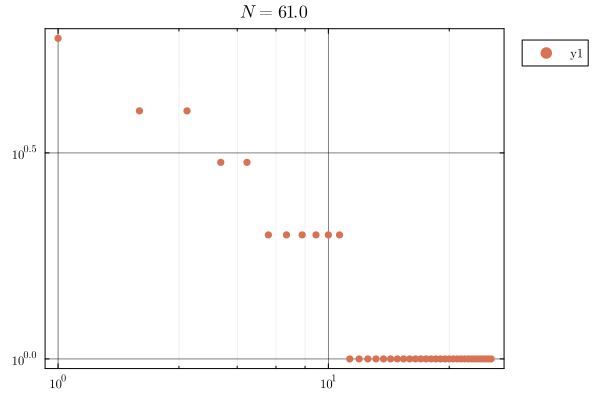

In [9]:
scatter(ic_sys, xaxis = :log10, yaxis = :log10, title = L"N=%$(sum(ic_sys))")

# So, let's start by observing the formation of condensate and tails

First for $\gamma=1.1$.

In [235]:
s10_2 = dsim.create_cell(0.6, 1.1, 1, 10^2, [1], :pdf)
s10_3 = dsim.create_cell(0.6, 1.1, 1, 10^3, s10_2, :pdf)
s10_4 = dsim.create_cell(0.6, 1.1, 1, 10^4, s10_3, :pdf)
s10_5 = dsim.create_cell(0.6, 1.1, 1, 10^5, s10_4, :pdf)
s10_6 = dsim.create_cell(0.6, 1.1, 1, 10^6, s10_5, :pdf)
s10_7 = dsim.create_cell(0.6, 1.1, 1, 10^7, s10_6, :pdf);

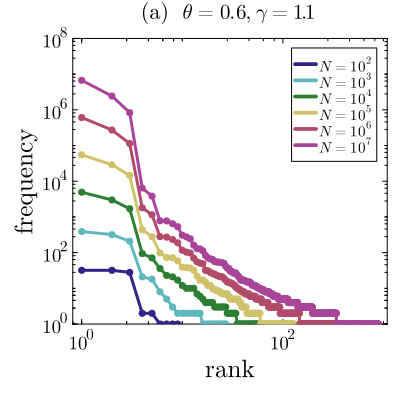

In [300]:
s10_s = [s10_2, s10_3, s10_4, s10_5, s10_6, s10_7]
p11 = plot(s10_2, xaxis = :log10, yaxis = :log10, c = cpal[1], lw = 3, label = L"N=10^2")
scatter!(s10_2, xaxis = :log10, yaxis = :log10, c = cpal[1], lw = 3, label = :none)
for i in 2:6
    plot!(s10_s[i], xaxis = :log10, yaxis = :log10, c = cpal[i], lw = 3, label = L"N=10^{%$(i+1)}")
    scatter!(s10_s[i], xaxis = :log10, yaxis = :log10, c = cpal[i], lw = 3, label = :none)
end
plot!(grid = :none, minorgrid = :none, size = (400,400), legend = :topright)
plot!(xlabelfontsize = 16, ylabelfontsize = 16, legendfontsize = 10, xtickfontsize = 12, ytickfontsize = 12, titlefontsize = 14)
plot!(title = L"(a)$\quad \theta = 0.6, \gamma=1.1$", xlabel = "rank", ylabel = "frequency", ylims = [1,10^8])

In [237]:
logxs = log10.([10^x for x in 2:7]);
logys = log10.(length.(s10_s));
df = DataFrame(y = logys, x = logxs);
glm = lm(@formula(y ~ x), df);
a,b = coef(glm)

2-element Vector{Float64}:
 0.20186899362263655
 0.3891049324135741

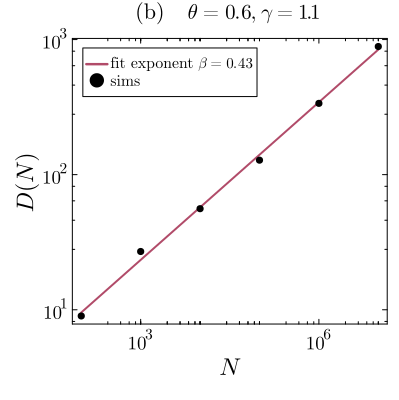

In [299]:
p12 = plot([10^2,10^7],[(10^a)*(10^2)^b, (10^a)*(10^7)^b], color = cpal[end-1], lw = 2, label = L"fit exponent $\beta = 0.43$")
scatter!([10^x for x in 2:7], length.(s10_s), xaxis = :log10, yaxis = :log10, label = "sims", c = :black)
plot!(grid = :none, minorgrid = :none, size = (400,400), legend = :topleft)
plot!(xlabelfontsize = 16, ylabelfontsize = 16, legendfontsize = 10, xtickfontsize = 12, ytickfontsize = 12, titlefontsize = 14)
plot!(title = L"(b) $\quad \theta = 0.6, \gamma=1.1$", xlabel = L"N", ylabel = L"D(N)")

First for $\gamma=1.5$.

In [176]:
s10_2b = dsim.create_cell(0.2, 1.5, 1, 10^2, [1], :pdf)
s10_3b = dsim.create_cell(0.2, 1.5, 1, 10^3, s10_2b, :pdf)
s10_4b = dsim.create_cell(0.2, 1.5, 1, 10^4, s10_3b, :pdf)
s10_5b = dsim.create_cell(0.2, 1.5, 1, 10^5, s10_4b, :pdf)
s10_6b = dsim.create_cell(0.2, 1.5, 1, 10^6, s10_5b, :pdf)
s10_7b = dsim.create_cell(0.2, 1.5, 1, 10^7, s10_6b, :pdf);

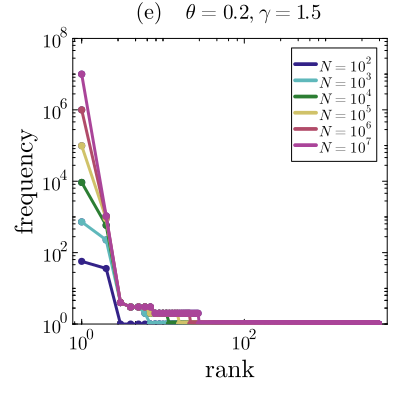

In [298]:
s10_sb = [s10_2b, s10_3b, s10_4b, s10_5b, s10_6b, s10_7b]
p21 = plot(s10_sb[1], xaxis = :log10, yaxis = :log10, c = cpal[1], lw = 3, label = L"N=10^2")
scatter!(s10_sb, xaxis = :log10, yaxis = :log10, c = cpal[1], lw = 3, label = :none)
for i in 2:6
    plot!(s10_sb[i], xaxis = :log10, yaxis = :log10, c = cpal[i], lw = 3, label = L"N=10^{%$(i+1)}")
    scatter!(s10_sb[i], xaxis = :log10, yaxis = :log10, c = cpal[i], lw = 3, label = :none)
end
plot!(grid = :none, minorgrid = :none, size = (400,400), legend = :topright)
plot!(xlabelfontsize = 16, ylabelfontsize = 16, legendfontsize = 10, xtickfontsize = 12, ytickfontsize = 12, titlefontsize = 14)
plot!(title = L"(e) $\quad \theta = 0.2, \gamma=1.5$", xlabel = "rank", ylabel = "frequency", ylims = [1,10^8])

In [178]:
logxs = log10.([10^x for x in 2:7]);
logys = log10.(length.(s10_sb));
dfb = DataFrame(y = logys, x = logxs);
glmb = lm(@formula(y ~ x), dfb);
ab,bb = coef(glmb)

2-element Vector{Float64}:
 -0.043226886014273214
  0.5325447877834563

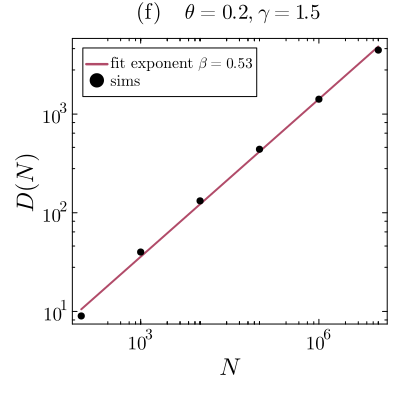

In [306]:
p22 = plot([10^2,10^7],[(10^ab)*(10^2)^bb, (10^ab)*(10^7)^bb], color = cpal[end-1], lw = 2, label = L"fit exponent $\beta = 0.53$")
scatter!([10^x for x in 2:7], length.(s10_sb), xaxis = :log10, yaxis = :log10, label = "sims", c = :black)
plot!(grid = :none, minorgrid = :none, size = (400,400), legend = :topleft)
plot!(xlabelfontsize = 16, ylabelfontsize = 16, legendfontsize = 10, xtickfontsize = 12, ytickfontsize = 12, titlefontsize = 14)
plot!(title = L"(f) $\quad \theta = 0.2, \gamma=1.5$", xlabel = L"N", ylabel = L"D(N)")

# Now, let's have a look at the $n_k$ scaling

## The first one.

In [239]:
kstar = 1+0.4/(0.1)

5.0

In [240]:
s10_s

6-element Vector{Vector{Int64}}:
 [32, 32, 28, 2, 2, 1, 1, 1, 1]
 [390, 320, 209, 21, 18, 8, 5, 3, 2, 2  …  1, 1, 1, 1, 1, 1, 1, 1, 1, 1]
 [4921, 2984, 1700, 94, 71, 36, 23, 21, 17, 12  …  1, 1, 1, 1, 1, 1, 1, 1, 1, 1]
 [55105, 28859, 14540, 436, 280, 98, 73, 72, 59, 39  …  1, 1, 1, 1, 1, 1, 1, 1, 1, 1]
 [609364, 271448, 113774, 1806, 1149, 281, 271, 234, 189, 117  …  1, 1, 1, 1, 1, 1, 1, 1, 1, 1]
 [6717321, 2432102, 833546, 6441, 3822, 780, 772, 647, 534, 307  …  1, 1, 1, 1, 1, 1, 1, 1, 1, 1]

First, $n_1$:

In [241]:
n1s = [count(==(1), a) for a in s10_s]

6-element Vector{Int64}:
   4
  12
  22
  69
 191
 549

In [242]:
logxs = log10.([10^x for x in 2:7]);
logys = log10.(n1s[1:end]);
dfc = DataFrame(y = logys, x = logxs)
glmc = lm(@formula(y ~ x), dfc)
ac,bc = coef(glmc)

2-element Vector{Float64}:
 -0.2543264158773884
  0.42255841540359995

In [243]:
α1 = 0.4

0.4

In [244]:
n2s = [count(==(2), a) for a in s10_s]

6-element Vector{Int64}:
   2
   7
   7
  16
  53
 143

In [245]:
logxs = log10.([10^x for x in 2:7]);
logys = log10.(n2s[1:end]);
dfd = DataFrame(y = logys, x = logxs);
glmd = lm(@formula(y ~ x), dfd);
ad,bd = coef(glmd)

2-element Vector{Float64}:
 -0.39816563572133634
  0.35051673258304766

In [246]:
α2 = 0.4-(1.1-1)

0.29999999999999993

In [247]:
n3s = [count(==(3), a) for a in s10_s]

6-element Vector{Int64}:
  0
  1
  7
  5
 22
 56

In [248]:
logxs = log10.([10^x for x in 3:7]);
logys = log10.(n3s[2:end]);
dfe = DataFrame(y = logys, x = logxs);
glme = lm(@formula(y ~ x), dfe);
ae,be = coef(glme)

2-element Vector{Float64}:
 -1.0699145969744404
  0.3993700694820354

In [249]:
α3 = 0.4-2*(1.1-1)

0.19999999999999984

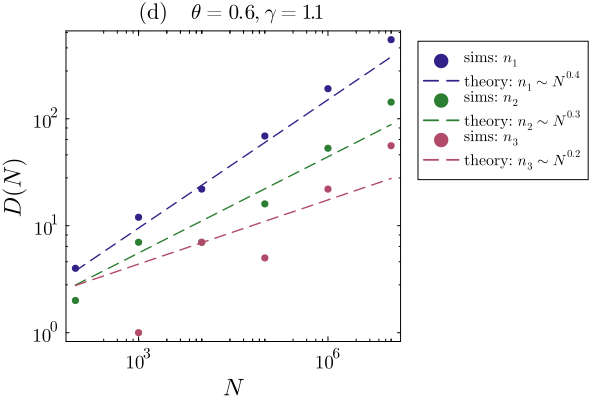

In [296]:
p14 = scatter([10^x for x in 2:7], n1s, xaxis = :log10, yaxis = :log10, c = cpal[1], label = L"sims: $n_1$")
plot!([10^2,10^7],[0.6*(10^2)^0.4, 0.6*(10^7)^0.4], linestyle = :dash, c = cpal[1], label = L"theory: $n_1\sim N^{0.4}$")

scatter!([10^x for x in 2:7], n2s, xaxis = :log10, yaxis = :log10, c = cpal[3], label = L"sims: $n_2$")
plot!([10^2,10^7],[0.7*(10^2)^0.3, 0.7*(10^7)^0.3], linestyle = :dash, c = cpal[3], label = L"theory: $n_2\sim N^{0.3}$")

scatter!([10^x for x in 3:7], n3s[2:end], xaxis = :log10, yaxis = :log10, c = cpal[5], label = L"sims: $n_3$")
plot!([10^2,10^7],[1.1*(10^2)^0.2, 1.1*(10^7)^0.2], linestyle = :dash, c = cpal[5], label = L"theory: $n_3\sim N^{0.2}$")

plot!(grid = :none, minorgrid = :none, size = (600,400))
plot!(xlabelfontsize = 16, ylabelfontsize = 16, legendfontsize = 10, xtickfontsize = 12, ytickfontsize = 12, titlefontsize = 14)
plot!(title = L"(d) $\quad \theta = 0.6, \gamma=1.1$", xlabel = L"N", ylabel = L"D(N)")

## The second one.

In [251]:
kstar = 1+0.5/(0.5)

2.0

In [252]:
s10_sb

6-element Vector{Vector{Int64}}:
 [57, 36, 1, 1, 1, 1, 1, 1, 1]
 [727, 227, 4, 3, 3, 2, 1, 1, 1, 1  …  1, 1, 1, 1, 1, 1, 1, 1, 1, 1]
 [9272, 584, 4, 3, 3, 3, 2, 2, 2, 2  …  1, 1, 1, 1, 1, 1, 1, 1, 1, 1]
 [98647, 897, 4, 3, 3, 3, 2, 2, 2, 2  …  1, 1, 1, 1, 1, 1, 1, 1, 1, 1]
 [997542, 1020, 4, 3, 3, 3, 3, 2, 2, 2  …  1, 1, 1, 1, 1, 1, 1, 1, 1, 1]
 [9994455, 1067, 4, 3, 3, 3, 3, 2, 2, 2  …  1, 1, 1, 1, 1, 1, 1, 1, 1, 1]

First, $n_1$:

In [253]:
n1sb = [count(==(1), a) for a in s10_sb]

6-element Vector{Int64}:
    7
   34
  121
  425
 1394
 4422

In [255]:
logxs = log10.([10^x for x in 3:7]);
logys = log10.(n1sb[2:end]);
df2 = DataFrame(y = logys, x = logxs)
glm2 = lm(@formula(y ~ x), df2)
a2,b2 = coef(glm2)

2-element Vector{Float64}:
 -0.0383715770404706
  0.5289757045846423

In [256]:
α1 = 0.5

0.5

In [257]:
n2sb = [count(==(2), a) for a in s10_sb]

6-element Vector{Int64}:
  0
  1
  5
  9
 14
 20

In [258]:
logxs = log10.([10^x for x in 3:7]);
logys = log10.(n2sb[2:end]);
df3 = DataFrame(y = logys, x = logxs);
glm3 = lm(@formula(y ~ x), df3);
a3,b3 = coef(glm3)

2-element Vector{Float64}:
 -0.7045349023115778
  0.30492180226701804

In [259]:
α2 = 0.5-(1.5-1)

0.0

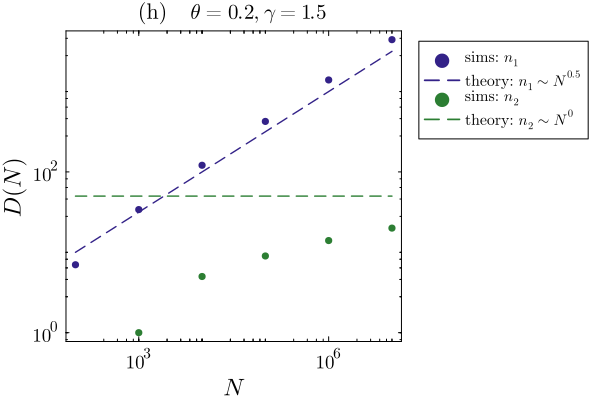

In [327]:
p24 = scatter([10^x for x in 2:7], n1sb, xaxis = :log10, yaxis = :log10, c = cpal[1], label = L"sims: $n_1$")
plot!([10^2,10^7],[1*(10^2)^0.5, 1*(10^7)^0.5], linestyle = :dash, c = cpal[1], label = L"theory: $n_1\sim N^{0.5}$")

scatter!([10^x for x in 3:7], n2sb[2:end], xaxis = :log10, yaxis = :log10, c = cpal[3], label = L"sims: $n_2$")
plot!([10^2,10^7],[50*(10^2)^0.0, 50*(10^7)^0.0], linestyle = :dash, c = cpal[3], label = L"theory: $n_2\sim N^{0}$")

plot!(grid = :none, minorgrid = :none, size = (600,400))
plot!(xlabelfontsize = 16, ylabelfontsize = 16, legendfontsize = 10, xtickfontsize = 12, ytickfontsize = 12, titlefontsize = 14)
plot!(title = L"(h) $\quad \theta = 0.2, \gamma=1.5$", xlabel = L"N", ylabel = L"D(N)")

# Scaling of largest function size

In [267]:
[x[1] for x in s10_s] 

6-element Vector{Int64}:
      32
     390
    4921
   55105
  609364
 6717321

In [269]:
logxs = log10.([10^x for x in 2:7]);
logys = log10.([x[1] for x in s10_s] );
df4 = DataFrame(y = logys, x = logxs);
glm4 = lm(@formula(y ~ x), df4);
a4,b4 = coef(glm4)

2-element Vector{Float64}:
 -0.5978481681881084
  1.0640229948896367

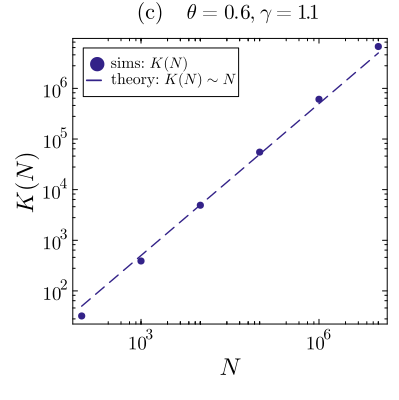

In [304]:
p13 = scatter([10^x for x in 2:7], [x[1] for x in s10_s] , xaxis = :log10, yaxis = :log10, c = cpal[1], label = L"sims: $K(N)$")
plot!([10^2,10^7],[0.5*(10^2)^1, 0.5*(10^7)^1], linestyle = :dash, c = cpal[1], label = L"theory: $K(N)\sim N$")

plot!(grid = :none, minorgrid = :none, size = (400,400), legend = :topleft)
plot!(xlabelfontsize = 16, ylabelfontsize = 16, legendfontsize = 10, xtickfontsize = 12, ytickfontsize = 12, titlefontsize = 14)
plot!(title = L"(c) $\quad \theta = 0.6, \gamma=1.1$", xlabel = L"N", ylabel = L"K(N)")

In [275]:
[x[1] for x in s10_sb] 

6-element Vector{Int64}:
      57
     727
    9272
   98647
  997542
 9994455

In [276]:
logxs = log10.([10^x for x in 2:7]);
logys = log10.([x[1] for x in s10_sb]);
df5 = DataFrame(y = logys, x = logxs);
glm5 = lm(@formula(y ~ x), df5);
a5,b5 = coef(glm5)

2-element Vector{Float64}:
 -0.2836790763297279
  1.0473863458036354

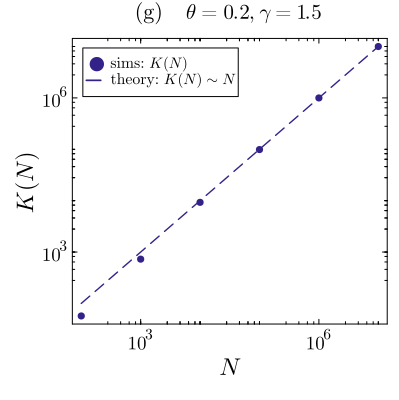

In [303]:
p23 = scatter([10^x for x in 2:7], [x[1] for x in s10_sb], xaxis = :log10, yaxis = :log10, c = cpal[1], label = L"sims: $K(N)$")
plot!([10^2,10^7],[1*(10^2)^1, 1*(10^7)^1], linestyle = :dash, c = cpal[1], label = L"theory: $K(N)\sim N$")

plot!(grid = :none, minorgrid = :none, size = (400,400), legend = :topleft)
plot!(xlabelfontsize = 16, ylabelfontsize = 16, legendfontsize = 10, xtickfontsize = 12, ytickfontsize = 12, titlefontsize = 14)
plot!(title = L"(g) $\quad \theta = 0.2, \gamma=1.5$", xlabel = L"N", ylabel = L"K(N)")

In [318]:
l = @layout [
    a{0.2w} b{0.2w} c{0.2w} d{0.4w}
    e{0.2w} f{0.2w} g{0.2w} h{0.4w}
]

2×4 Matrix{Any}:
 (label = :a, width = 0.2, height = :auto)  …  (label = :d, width = 0.4, height = :auto)
 (label = :e, width = 0.2, height = :auto)     (label = :h, width = 0.4, height = :auto)

In [321]:
using Plots.Measures

In [329]:
plot(p11,p12,p13,p14,p21,p22,p23,p24, layout = l, size = (1500,600), bottom_margin = 10mm, top_margin = 2mm, left_margin = 10mm, right_margin = 2mm)
savefig("./superlinear_results.pdf")

"/home/jamesh/GitHub/Ecological-Preferential-Attachment/Calibrations/superlinear_results.pdf"